# Student Academic Performance Prediction

Compare Logistic Regression and KNN for predicting student performance
categories using the Student Performance Factors dataset.

## 1. Load and inspect the dataset

In [1]:
from pathlib import Path
import pandas as pd

# Support execution from either the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "raw" / "StudentPerformanceFactors.csv"
)

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

Rows: 6,607
Columns: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head(5))

print("\nLast five rows:")
display(df.tail(5))

# Includes numeric and categorical summaries.
display(df.describe(include="all").T)

Dataset dimensions: (6607, 20)

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

First five rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Last five rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [30]:
quality_checks = pd.Series({
    "Attendance outside 0–100":
        (~df["Attendance"].between(0, 100)).sum(),

    "Previous score outside assumed 0–100":
        (~df["Previous_Scores"].between(0, 100)).sum(),

    "Exam score outside assumed 0–100":
        (~df["Exam_Score"].between(0, 100)).sum(),

    "Weekly study hours outside 0–168":
        (~df["Hours_Studied"].between(0, 168)).sum(),

    "Daily sleep hours outside 0–24":
        (~df["Sleep_Hours"].between(0, 24)).sum(),

    "Negative tutoring-session counts":
        (df["Tutoring_Sessions"] < 0).sum(),

    "Non-integer tutoring-session counts":
        (df["Tutoring_Sessions"].dropna() % 1 != 0).sum(),

    "Unexpected non-missing resource categories":
        (
            df["Access_to_Resources"].notna()
            & ~df["Access_to_Resources"].isin(["Low", "Medium", "High"])
        ).sum(),
})

display(quality_checks.to_frame("flagged_rows"))

,flagged_rows
Attendance outside 0–100,0
Previous score outside assumed 0–100,0
Exam score outside assumed 0–100,1
Weekly study hours outside 0–168,0
Daily sleep hours outside 0–24,0
Negative tutoring-session counts,0
Non-integer tutoring-session counts,0
Unexpected non-missing resource categories,0


### Validation findings

The range and category checks flagged one row with Exam_Score = 101.
This row was excluded from the modeling dataset under the documented
0–100 score-range assumption.

In [5]:
inspection = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique()
})

display(inspection)
print("Duplicate rows:", df.duplicated().sum())

,data_type,missing_count,missing_percent,unique_values
Hours_Studied,int64,0,0.00,41
Attendance,int64,0,0.00,41
Parental_Involvement,str,0,0.00,3
Access_to_Resources,str,0,0.00,3
Extracurricular_Activities,str,0,0.00,2
Sleep_Hours,int64,0,0.00,7
Previous_Scores,int64,0,0.00,51
Motivation_Level,str,0,0.00,3
Internet_Access,str,0,0.00,2
Tutoring_Sessions,int64,0,0.00,9


Duplicate rows: 0


In [ ]:
display(df["Exam_Score"].describe())

print("Missing exam scores:", df["Exam_Score"].isna().sum())
print(
    "Scores outside 0-100:",
    ((df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)).sum()
)

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Missing exam scores: 0
Scores outside 0–100: 1


## 2. Feature selection and target definition

The original dataset contains 20 columns. For this demonstration,
four input features are selected to match the assessment's suggested
study-related and academic indicators:

- Hours_Studied
- Attendance
- Previous_Scores
- Sleep_Hours
- Tutoring_Sessions
- Access_to_Resources

Hours_Studied is recorded per week, whereas the assessment suggests
daily study hours. The original weekly unit is retained and documented.

Assignments completed is unavailable and is therefore omitted.

Exam_Score will be used only to derive the Pass/Fail target and will
not be included as an input feature.

The proposed demonstration rule is Pass for Exam_Score >= 70 and
Fail otherwise. This is a project assumption, not an official passing
rule supplied with the dataset.

Missing values occur in three excluded columns. The four selected
inputs and Exam_Score have no missing values in the initial inspection.

One Exam_Score value exceeds the assumed 0–100 range; its handling
will be documented before modeling.

### Additional features and reasons for inclusion

Two additional features were selected alongside the four fields that
closely match the assessment's suggestions:

| Feature | Reason for inclusion |
|---------|----------------------|
| Tutoring_Sessions | Represents additional academic support received through tutoring, which may be associated with exam performance. |
| Access_to_Resources | Represents access to learning resources, which may influence a student's opportunities to study and prepare for exams. |

These are separate input features, not substitutes for the unavailable
assignments_completed field. Their inclusion does not guarantee better
predictions or establish a causal relationship with exam performance.

In [11]:
FEATURE_COLUMNS = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
    "Access_to_Resources",
]

display(df[FEATURE_COLUMNS].describe().T)

print("Missing values in selected inputs:")
print(df[FEATURE_COLUMNS].isna().sum())




,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0


Missing values in selected inputs:
Hours_Studied          0
Attendance             0
Previous_Scores        0
Sleep_Hours            0
Tutoring_Sessions      0
Access_to_Resources    0
dtype: int64


In [ ]:
PASS_THRESHOLD = 70

proposed_result = df["Exam_Score"].ge(PASS_THRESHOLD).map({
    True: "Pass",
    False: "Fail",
})

# Show the number and percentage of each class.
class_summary = pd.DataFrame({
    "count": proposed_result.value_counts(),
    "percentage": (
        proposed_result.value_counts(normalize=True) * 100
    ).round(2),
})

print(f"\nProposed class distribution (threshold: {PASS_THRESHOLD}):")
display(class_summary)

# Inspect the row whose exam score is outside the assumed range.
print("\nRows with exam scores outside 0-100:")
display(df.loc[~df["Exam_Score"].between(0, 100)])


Proposed class distribution (threshold: 70):


,count,percentage
Exam_Score,,
Fail,4982,75.4
Pass,1625,24.6



Rows with exam scores outside 0–100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [13]:
print("Access_to_Resources categories:")
print(df["Access_to_Resources"].value_counts(dropna=False))

Access_to_Resources categories:
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64


### Data-quality summary and preprocessing decisions

- The original dataset contains 6,607 rows and 20 columns.
- No exact duplicate rows were found, so no duplicate rows were removed.
- Missing values were found in Teacher_Quality (78),
  Parental_Education_Level (90), and Distance_from_Home (67).
- These three columns are outside the selected six-feature scope.
  Rows were not removed because of missing values in these unused columns.
- The six selected inputs and Exam_Score have no missing values in
  the initial inspection, so missing-value imputation is not currently
  necessary for the modeling dataset.
- One row has Exam_Score = 101. Under the documented assumption that
  scores range from 0 to 100, this row is excluded from modeling.
  Its correct score cannot be verified, so it is not replaced with 100.
- The original dataframe is preserved. Reproducible filtering creates
  a separate modeling dataframe containing 6,606 rows.
- Additional checks flag invalid input ranges and unexpected categories.
  Flagged values require review before any further cleaning.
- Exam_Score is used only to derive the target. Neither Exam_Score nor
  final_result is included in the input features.
- Scaling and categorical encoding will be performed inside the model
  pipelines and fitted only on training data.

## 3. Prepare the modeling dataset

Six input features are selected. They contain no missing values in the
initial inspection. No exact duplicate rows were found in the source data.

One row has Exam_Score = 101. Assuming an exam-score range of 0–100,
this row is excluded from modeling because its correct score cannot
be verified. The original dataframe is preserved.

Pass/Fail labels are derived using a fixed demonstration threshold:
Pass for Exam_Score >= 70; Fail otherwise. This is a project assumption,
not an official passing rule from the dataset.

Fail is encoded as 1 (the positive class), and Pass as 0.
Exam_Score is excluded from the model inputs to prevent target leakage.

In [20]:
# Keep only rows with an exam score within the assumed valid range.
valid_score_mask = df["Exam_Score"].between(0, 100)
model_df = df.loc[
    valid_score_mask,
    FEATURE_COLUMNS + ["Exam_Score"]
].copy()
model_df.info()

<class 'pandas.DataFrame'>
Index: 6606 entries, 0 to 6606
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Hours_Studied        6606 non-null   int64
 1   Attendance           6606 non-null   int64
 2   Previous_Scores      6606 non-null   int64
 3   Sleep_Hours          6606 non-null   int64
 4   Tutoring_Sessions    6606 non-null   int64
 5   Access_to_Resources  6606 non-null   str  
 6   Exam_Score           6606 non-null   int64
dtypes: int64(6), str(1)
memory usage: 444.7 KB


In [25]:
# Fail = 1 (positive class); Pass = 0.
PASS_THRESHOLD = 70
model_df["final_result"] = (
    model_df["Exam_Score"] < PASS_THRESHOLD
).astype(int)

model_df.head(5)


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Tutoring_Sessions,Access_to_Resources,Exam_Score,final_result
0,23,84,73,7,0,High,67,1
1,19,64,59,8,2,Medium,61,1
2,24,98,91,7,2,Medium,74,0
3,29,89,98,8,1,Medium,71,0
4,19,92,65,6,3,Medium,70,0


In [27]:
# Separate inputs from the target.
X = model_df[FEATURE_COLUMNS].copy()
y = model_df["final_result"].copy()

print("Rows excluded:", (~valid_score_mask).sum())
print("Input shape:", X.shape)
print("\nTarget counts:")
print(y.map({1: "Fail", 0: "Pass"}).value_counts())

Rows excluded: 1
Input shape: (6606, 6)

Target counts:
final_result
Fail    4982
Pass    1624
Name: count, dtype: int64


In [32]:
assert "Exam_Score" not in X.columns
assert "final_result" not in X.columns
assert X.columns.tolist() == FEATURE_COLUMNS
assert X.index.equals(y.index)
assert set(y.unique()) == {0, 1}

print("Confirmed: inputs and target are separated and aligned.")
print("\nMissing values in model inputs:")
print(X.isna().sum())

Confirmed: inputs and target are separated and aligned.

Missing values in model inputs:
Hours_Studied          0
Attendance             0
Previous_Scores        0
Sleep_Hours            0
Tutoring_Sessions      0
Access_to_Resources    0
dtype: int64


## 4. Train/test split and validation strategy

The modeling dataset is split into 80% training data and 20% held-out
test data.

- test_size=0.20: reserves 20% for final evaluation.
- random_state=42: makes the split reproducible when the dataset and
  row order remain unchanged.
- stratify=y:  preserves approximately the same Pass/Fail proportions
  in both sets, which is important because the classes are imbalanced.

### Validation and model selection

A separate fixed validation set is not used. Instead, five-fold
stratified cross-validation will be performed within the training set.

In each fold, the pipeline is fitted on four portions and evaluated on
the remaining portion. Each portion serves as validation data once.
Stratification approximately preserves class proportions in each fold.

Logistic Regression and KNN will be compared using the same folds.
Any hyperparameter tuning will use only training-set cross-validation.

Scaling and categorical encoding will be included inside each pipeline
so that preprocessing is fitted only on the training portion of each
fold.

### Evaluation criteria

Fail is encoded as 1 and treated as the positive class. Model selection
will primarily consider cross-validation macro F1, which gives both
classes equal weight. Fail-class recall and precision will also be
reviewed because missed support needs and unnecessary alerts both matter.

The selected configuration will be refitted on the full training set.
Both required classifiers will be evaluated on the held-out test set
using accuracy, precision, recall, F1-score, and confusion matrices.

Test results will be reported without using them to tune the models
or revise feature selection. The test set remains separate from
detailed exploratory analysis and model selection.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5284, 6)
Testing shape: (1322, 6)


## 5. Exploratory data analysis

Exploratory analysis is performed on the training set. The held-out
test set is reserved for final evaluation.

We examine:
1. Pass/Fail class distribution.
2. Numeric feature distributions by result.
3. Pass/Fail proportions by access to learning resources.

These plots describe associations in this dataset, not causal effects.
Pass/Fail labels use the project's assumed exam-score threshold of 70.

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Indices align each training row with its target label.
train_eda = X_train.copy()
train_eda["Result"] = y_train.map({1: "Fail", 0: "Pass"})

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULT_ORDER = ["Fail", "Pass"]

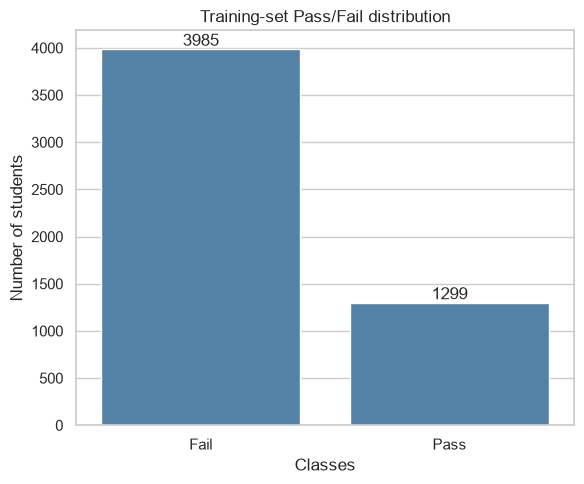

In [36]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.countplot(
    data=train_eda,
    x="Result",
    order=RESULT_ORDER,
    color="steelblue",
    ax=ax,
)

ax.set_title("Training-set Pass/Fail distribution")
ax.set_xlabel("Classes")
ax.set_ylabel("Number of students")
ax.bar_label(ax.containers[0])

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=150)
plt.show()

### EDA observations and limitations

**Class imbalance:** The training set contains 3,985 Fail labels
   and 1,299 Pass labels—approximately 75.4% and 24.6%, respectively.
   Always predicting Fail would achieve about 75.4% training accuracy,
   despite identifying none of the Pass cases. Accuracy alone is
   therefore insufficient; both classes' performance must be examined.

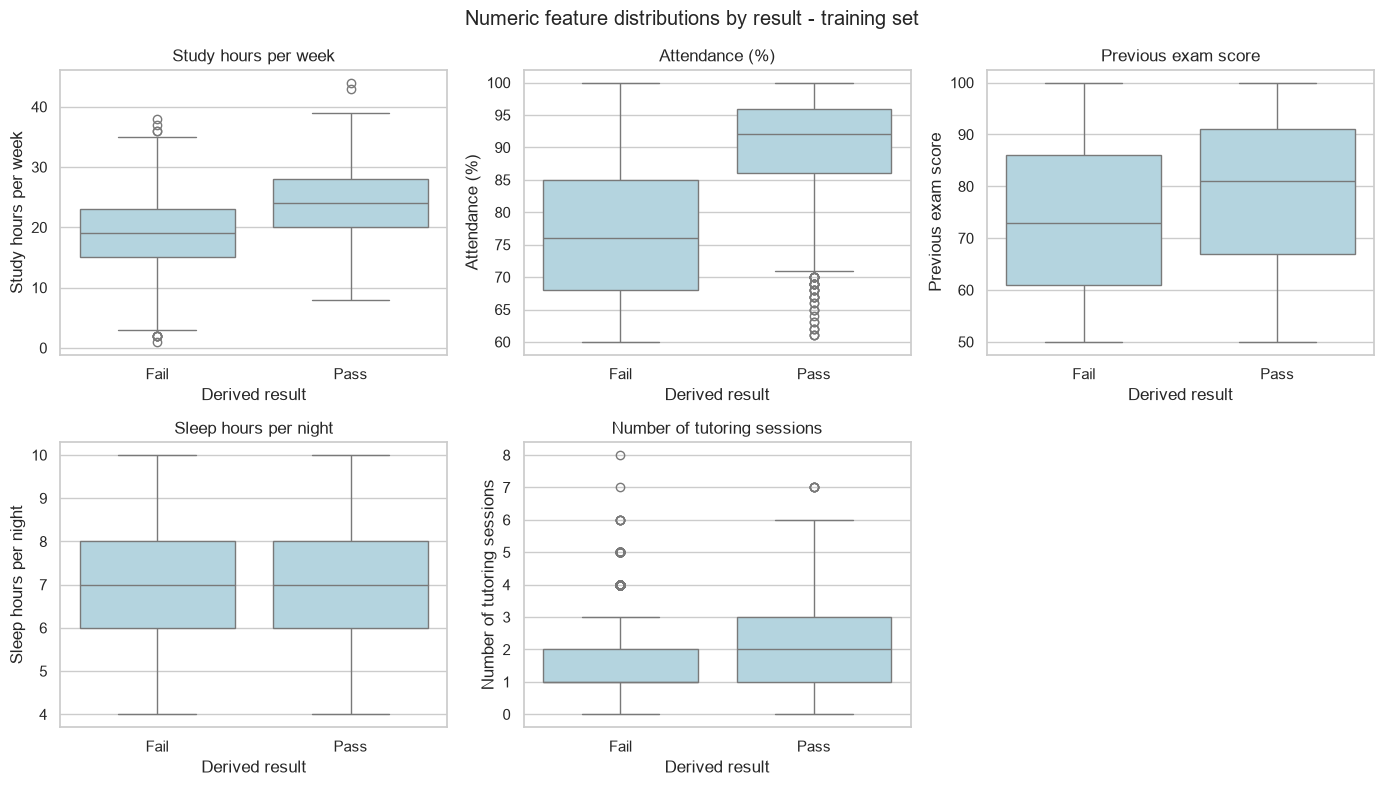

In [40]:
numeric_labels = {
    "Hours_Studied": "Study hours per week",
    "Attendance": "Attendance (%)",
    "Previous_Scores": "Previous exam score",
    "Sleep_Hours": "Sleep hours per night",
    "Tutoring_Sessions": "Number of tutoring sessions",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (column, label) in zip(axes.flat, numeric_labels.items()):
    sns.boxplot(
        data=train_eda,
        x="Result",
        y=column,
        order=RESULT_ORDER,
        color="lightblue",
        ax=ax,
    )
    ax.set_title(label)
    ax.set_xlabel("Derived result")
    ax.set_ylabel(label)

axes.flat[-1].set_visible(False)

fig.suptitle("Numeric feature distributions by result - training set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_numeric_features.png", dpi=150)
plt.show()

 **Study hours:** The Pass group has a higher median weekly study
   time, approximately 24 hours compared with 19 hours for the Fail
   group. However, the distributions overlap, so study hours alone
   do not perfectly distinguish the classes.

**Attendance:** Median attendance is approximately 92% in the Pass
   group and 76% in the Fail group. This shows an association between
   attendance and the derived result, but does not establish causation.

**Other numeric features:** The Pass group has higher median previous
   scores and tutoring-session counts. Sleep-hour distributions look
   similar across the two classes, with a median of about seven hours.
   This plot alone does not establish that sleep is unimportant.

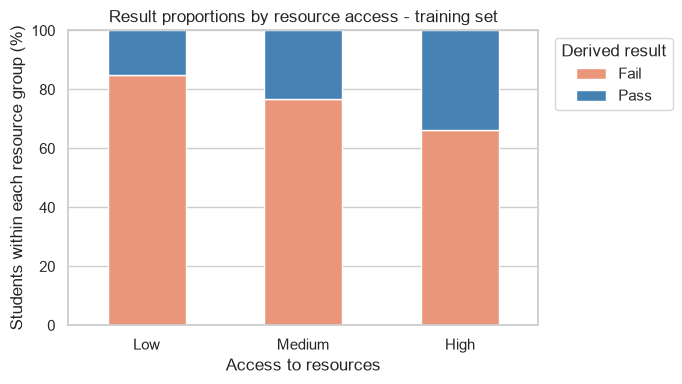

Result,Fail,Pass
Access_to_Resources,,
Low,85.00,15.00
Medium,76.82,23.18
High,66.39,33.61


In [41]:
resource_proportions = pd.crosstab(
    train_eda["Access_to_Resources"],
    train_eda["Result"],
    normalize="index",
).reindex(
    index=["Low", "Medium", "High"],
    columns=RESULT_ORDER,
    fill_value=0,
).mul(100)

ax = resource_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    color=["#e9967a", "#4682b4"],
)

ax.set_title("Result proportions by resource access - training set")
ax.set_xlabel("Access to resources")
ax.set_ylabel("Students within each resource group (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Derived result",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_resource_access.png", dpi=150)
plt.show()

display(resource_proportions.round(2))

**Resource access:** The proportion labelled Pass increases from
   approximately 15% for Low resource access to 24% for Medium and 34%
   for High. These are within-group percentages, not raw student counts.
   Other factors may contribute to the observed differences.